# C2 Dispatch Rules Validation — 6 CCP

Experiment: `experiment_6ccp_1btg_dispatch_rules`

Levers: `t2_min_count` ∈ {1, 2}, `t2_min_wait_min` ∈ {0, 30, 60, 120} → 8 dispatch policies.

For each policy: T1 BCAS death rate and T2 NATO timeline compliance, side by side across BCAS rate levels.

In [15]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

FOLDER_NAME = "20260601_162817_scenario_6ccp_1btg"
run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME

df = pd.read_csv(run_folder / "results.csv")

df["policy_label"] = (
    "count=" + df["t2_min_count"].astype(int).astype(str)
    + "  wait=" + df["t2_min_wait_min"].astype(int).astype(str)
)

bcas_levels = sorted(df["bcas_rate"].unique())
bcas_lo, bcas_hi = bcas_levels[0], bcas_levels[-1]
policies = sorted(df["policy_label"].unique())

print(f"Loaded {len(df)} runs  |  bcas_rate: low={bcas_lo}, high={bcas_hi}")
print(f"Policies ({len(policies)}): {policies}")


def plot_policy(policy_label):
    """One figure for a single dispatch policy: T1 mortality + T2 NATO compliance."""
    sub = df[df["policy_label"] == policy_label]
    lo = sub[sub["bcas_rate"] == bcas_lo]
    hi = sub[sub["bcas_rate"] == bcas_hi]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # ── Left: T1 BCAS Death Rate ────────────────────────────────────────────
    ax = axes[0]
    data = [lo["death_rate_T1_BCAS"].dropna().values,
            hi["death_rate_T1_BCAS"].dropna().values]
    bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
                    patch_artist=True, widths=0.45, showfliers=False)
    colors = ["#3498db", "#e74c3c"]
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.7)
    for i, d in enumerate(data):
        if len(d):
            med = np.median(d)
            ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=10, fontweight="bold")
    ax.set_ylabel("Death Rate")
    ax.set_title("T1 BCAS Mortality", fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    # ── Right: T2 NATO Timeline Compliance ──────────────────────────────────
    ax = axes[1]
    data = [lo["frac_t2_within_timeline"].dropna().values,
            hi["frac_t2_within_timeline"].dropna().values]
    bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
                    patch_artist=True, widths=0.45, showfliers=False)
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.7)
    for i, d in enumerate(data):
        if len(d):
            med = np.median(d)
            ax.text(i + 1, med, f"  {med:.1%}", va="center", fontsize=10, fontweight="bold")
    ax.set_ylabel("Fraction Within Timeline")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
    ax.set_title("T2 NATO Timeline", fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    fig.suptitle(f"Policy: {policy_label}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

Loaded 360 runs  |  bcas_rate: low=0.03, high=0.07
Policies (6): ['count=1  wait=120', 'count=1  wait=30', 'count=1  wait=60', 'count=2  wait=120', 'count=2  wait=30', 'count=2  wait=60']


C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["policy_label"] = (


In [ ]:
plot_policy("count=1  wait=0")

C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],


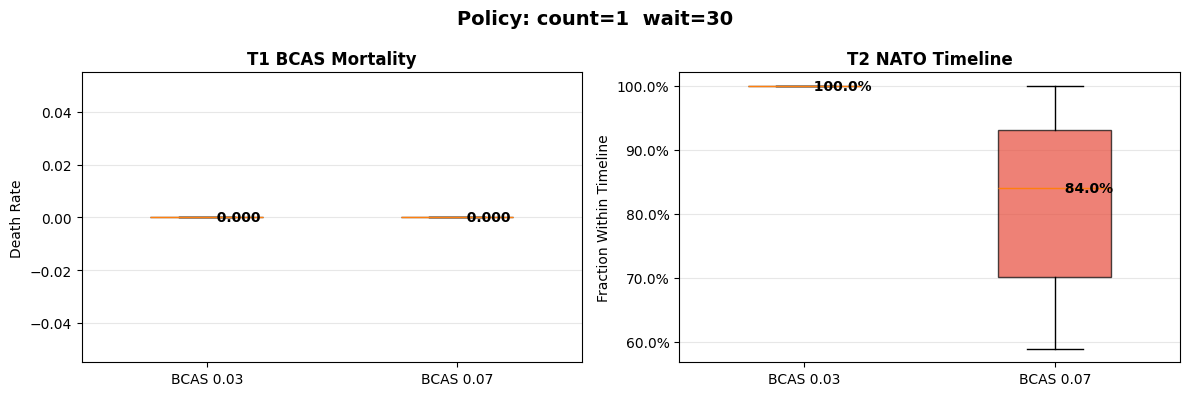

In [16]:
plot_policy("count=1  wait=30")

C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],


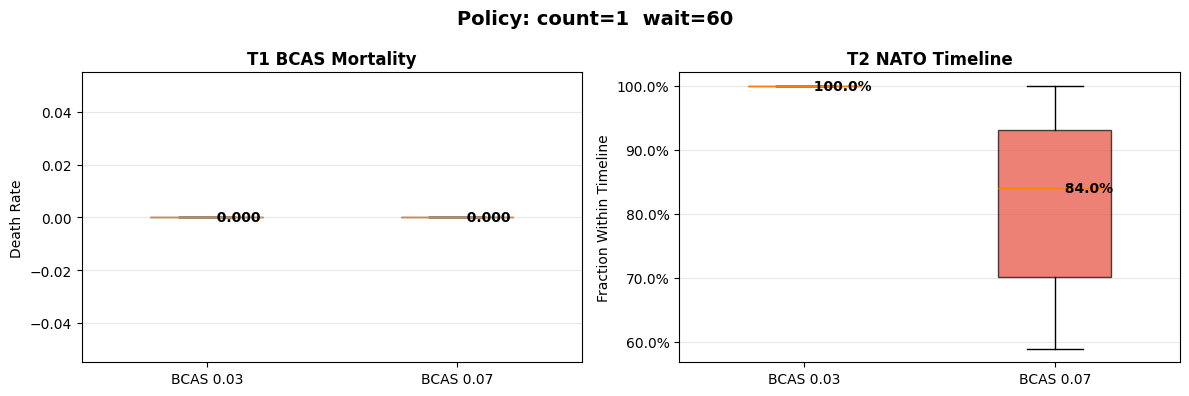

In [17]:
plot_policy("count=1  wait=60")

C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],


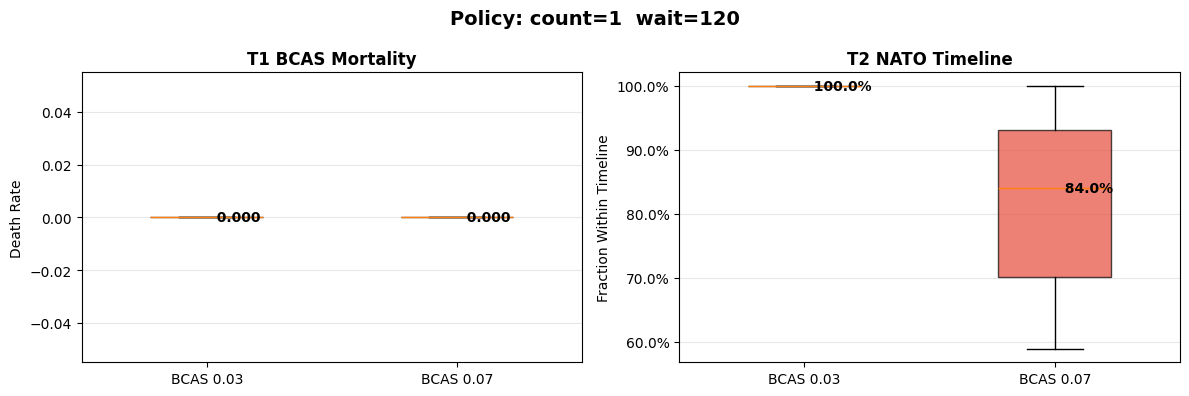

In [18]:
plot_policy("count=1  wait=120")

In [ ]:
plot_policy("count=2  wait=0")

C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],


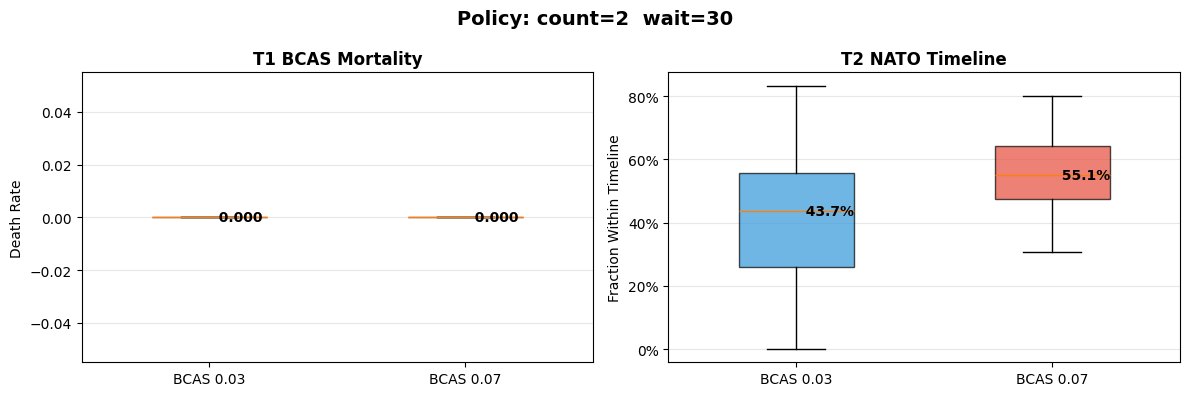

In [19]:
plot_policy("count=2  wait=30")

C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],


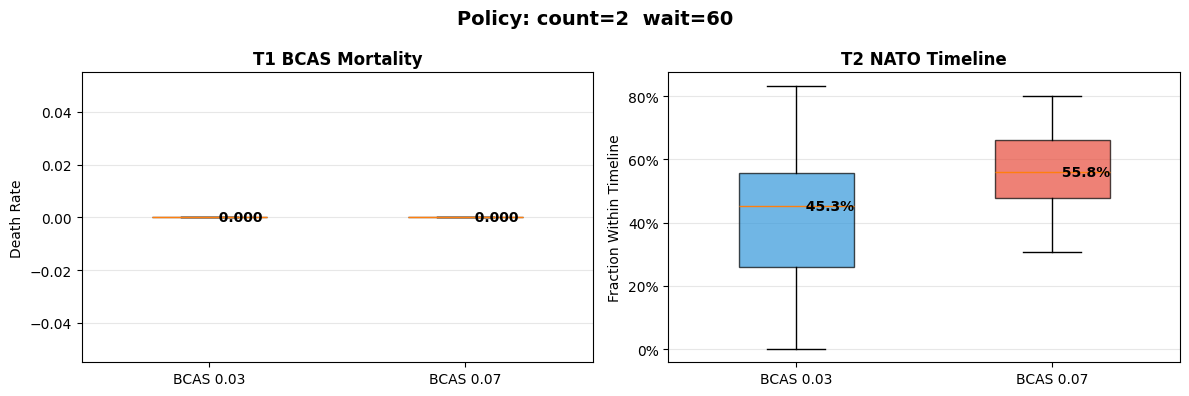

In [20]:
plot_policy("count=2  wait=60")

C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],
C:\Users\User\AppData\Local\Temp\ipykernel_28688\4270205880.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f"BCAS {bcas_lo}", f"BCAS {bcas_hi}"],


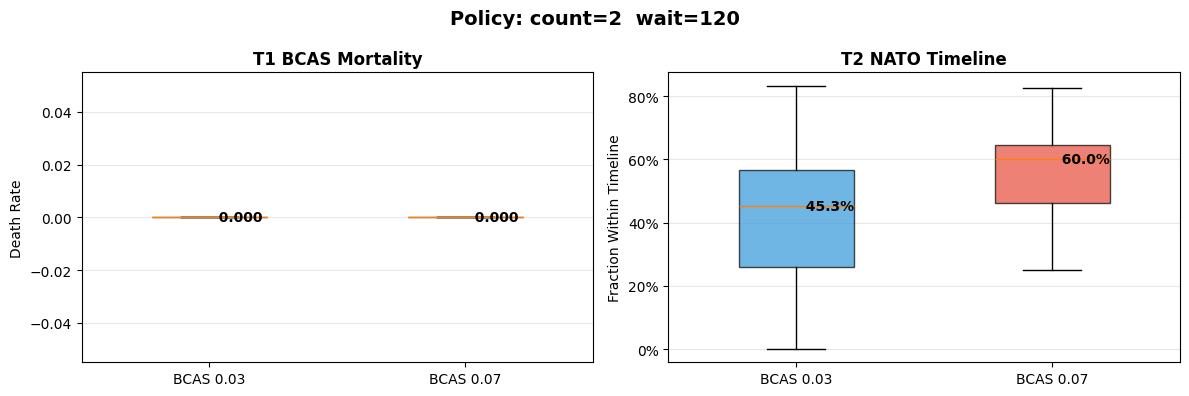

In [21]:
plot_policy("count=2  wait=120")